# DanaShift
### Multilingual Intelligent Customer Support Agent
**Applied Natural Language Processing Program · SDAIA Academy**

Developed as part of the Applied Natural Language Processing Program offered by SDAIA Academy, affiliated with the Saudi Data and Artificial Intelligence Authority (SDAIA).

## Project overview
Technical consulting teams receive customer requests in different Arabic dialects and English. DanaShift explores an NLP-driven approach to understanding these messages, protecting personal information, routing requests by intent, and retrieving relevant support cases to assist staff in preparing accurate responses.

**Target use cases:** cloud services, cybersecurity, automation projects, engineering meetings and proposals. Unrelated requests are out of scope.

**Proposed workflow:** request → privacy protection → intent and urgency → entity extraction → semantic retrieval → tool routing → human-reviewed response.

This notebook presents the experimental NLP components and recorded results. The classification experiment covers four intents; urgency prediction, full entity extraction and live tool integration remain proposed. No customer messages are sent automatically.


## 1. Privacy-aware multilingual preprocessing
Normalize Arabic requests, mask personal identifiers and audit tokenization.

In [ ]:
# Installation


!pip install -q transformers pandas matplotlib


In [ ]:
# Import Libraries


import pandas as pd

import re

import matplotlib.pyplot as plt

from transformers import AutoTokenizer

In [ ]:
# Create Dataset


# 🏷️ Project Name

project_name = "DanaShift Consulting"


# 📝 Project Dataset

data = {

    "language": ["ar", "ar", "ar", "en", "en", "en"],

    "text": [

        "  اشكر فريق الاستشاره  ",

        "أواجه    مشكلة   في الخطه",

        "  أحتاج اتواصل مع المهندس سلطان ",

        "  I would thank the consulting team  ",

        "i face a problem in the plan ",

        "  I need to be in touch with eng.Sultan "

    ]

}


# 📊 Create DataFrame

df = pd.DataFrame(data)


# ✅ Confirmation

print("🧪 Project:", project_name)

print("✅ Dataset created successfully!")


# 📊 Display Dataset

display(df)

🧪 Project: DanaShift Consulting
✅ Dataset created successfully!


,language,text
0,ar,اشكر فريق الاستشاره
1,ar,أواجه مشكلة في الخطه
2,ar,أحتاج اتواصل مع المهندس سلطان
3,en,I would thank the consulting team
4,en,i face a problem in the plan
5,en,I need to be in touch with eng.Sultan


In [ ]:
# Text Normalisation


import re

from IPython.display import HTML, display


def normalize(text):

    return re.sub(r"\s+", " ", str(text)).strip()


df["clean_text"] = df["text"].apply(normalize)


print("✅ Normalisation Completed!")

display(HTML(df[["text", "clean_text"]].to_html(index=False)))

✅ Normalisation Completed!


text,clean_text
اشكر فريق الاستشاره,اشكر فريق الاستشاره
أواجه مشكلة في الخطه,أواجه مشكلة في الخطه
أحتاج اتواصل مع المهندس سلطان,أحتاج اتواصل مع المهندس سلطان
I would thank the consulting team,I would thank the consulting team
i face a problem in the plan,i face a problem in the plan
I need to be in touch with eng.Sultan,I need to be in touch with eng.Sultan


In [ ]:
# PII Masking
import re

# 📝 Add Sample Personal Information (DanaShift Consulting)
df.loc[0, "clean_text"] = (
    "شكرا لفريق الاستشارة على خطة التحول الرقمي "
    "تواصلوا معي على [PHONE] أو [EMAIL]"
)

df.loc[1, "clean_text"] = (
    "أحتاج موعد مع المهندس سلطان لمراجعة الخطة "
    "رقمي ٠٥٠٩٨٧٦٥٤٣ وإيميلي [EMAIL]"
)



df.loc[2, "clean_text"] = (
    "لإتمام عقد الاستشارة هذه هويتي [NATIONAL_ID] "
    "والآيبان [IBAN]"
)

df.loc[3, "clean_text"] = (
    "Thank you for the  plan. "
    "Contact me at [PHONE] or [EMAIL]"
)

df.loc[4, "clean_text"] = (
    "Please call our CTO on [PHONE] "
    "about invoice INV-2026-0042 for 15000 SAR"
)

df.loc[5, "clean_text"] = (
    "I need a meeting with Eng. Sultan about the proposal. "
    "My email is [EMAIL]"
)




# 🛡️ Define Masking Function

def mask_pii(text):

    text = str(text)


    # Mask Email Addresses

    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b', '[EMAIL]', text)


    # Mask Saudi Mobile Numbers

    text = re.sub(r'\b05\d{8}\b', '[PHONE]', text)


    return text


# 🔒 Apply Masking

df["masked_text"] = df["clean_text"].apply(mask_pii)


# 📊 Display Results

display(df[["clean_text", "masked_text"]])

,clean_text,masked_text
0,شكرا لفريق الاستشارة على خطة التحول الرقمي توا...,شكرا لفريق الاستشارة على خطة التحول الرقمي توا...
1,أحتاج موعد مع المهندس سلطان لمراجعة الخطة رقمي...,أحتاج موعد مع المهندس سلطان لمراجعة الخطة رقمي...
2,لإتمام عقد الاستشارة هذه هويتي [NATIONAL_ID] والآ...,لإتمام عقد الاستشارة هذه هويتي [NATIONAL_ID] والآ...
3,Thank you for the plan. Contact me at 0561112...,Thank you for the plan. Contact me at [PHONE]...
4,Please call our CTO on [PHONE] about inv...,Please call our CTO on [PHONE] about inv...
5,I need a meeting with Eng. Sultan about the pr...,I need a meeting with Eng. Sultan about the pr...


In [ ]:

# Tokenisation


# 🤖 Load Tokenizer

tokenizer = AutoTokenizer.from_pretrained(

    "distilbert-base-multilingual-cased"

)


# 🔤 Apply Tokenisation

df["tokens"] = df["masked_text"].apply(

    tokenizer.tokenize

)


# 📊 Display Results

print("✅ Tokenisation Completed!")

display(df[["masked_text", "tokens"]])

✅ Tokenisation Completed!


,masked_text,tokens
0,شكرا لفريق الاستشارة على خطة التحول الرقمي توا...,"[ش, ##كر, ##ا, ل, ##فر, ##يق, ال, ##است, ##شار..."
1,أحتاج موعد مع المهندس سلطان لمراجعة الخطة رقمي...,"[أ, ##حت, ##اج, م, ##وع, ##د, مع, ال, ##مه, ##..."
2,لإتمام عقد الاستشارة هذه هويتي [NATIONAL_ID] والآ...,"[ل, ##إ, ##تمام, عقد, ال, ##است, ##شار, ##ة, ه..."
3,Thank you for the plan. Contact me at [PHONE]...,"[Thank, you, for, the, plan, ., Contact, me, a..."
4,Please call our CTO on [PHONE] about inv...,"[Please, call, our, CT, ##O, on, +, 966, ##55,..."
5,I need a meeting with Eng. Sultan about the pr...,"[I, need, a, meeting, with, Eng, ., Sultan, ab..."


In [ ]:
# Token Count


# 🔢 Count Tokens

df["token_count"] = df["tokens"].apply(len)


# 📊 Display Results

print("✅ Token Count Completed!")

display(df[["masked_text", "tokens", "token_count"]])

✅ Token Count Completed!


,masked_text,tokens,token_count
0,شكرا لفريق الاستشارة على خطة التحول الرقمي توا...,"[ش, ##كر, ##ا, ل, ##فر, ##يق, ال, ##است, ##شار...",37
1,أحتاج موعد مع المهندس سلطان لمراجعة الخطة رقمي...,"[أ, ##حت, ##اج, م, ##وع, ##د, مع, ال, ##مه, ##...",30
2,لإتمام عقد الاستشارة هذه هويتي [NATIONAL_ID] والآ...,"[ل, ##إ, ##تمام, عقد, ال, ##است, ##شار, ##ة, ه...",35
3,Thank you for the plan. Contact me at [PHONE]...,"[Thank, you, for, the, plan, ., Contact, me, a...",21
4,Please call our CTO on [PHONE] about inv...,"[Please, call, our, CT, ##O, on, +, 966, ##55,...",30
5,I need a meeting with Eng. Sultan about the pr...,"[I, need, a, meeting, with, Eng, ., Sultan, ab...",20


In [ ]:
# Tokenizer Audit


# 📊 Calculate Fertility

df["fertility"] = df["token_count"] / df["masked_text"].str.split().str.len()


# 🔍 Calculate UNK Rate

total = df["token_count"].sum()

unknown = sum(t.count(tokenizer.unk_token) for t in df["tokens"])


# ✅ Display Results

print("🧪 Project:", project_name)


print("\n🌐 Average Fertility:")

print(df.groupby("language")["fertility"].mean().round(2))


print("\n📏 p95 Sequence Length:", round(df["token_count"].quantile(0.95), 2))

print("🔍 UNK Rate:", round(unknown / total, 4) if total else 0)


print("✅ Tokenizer Audit Completed!")

🧪 Project: DanaShift Consulting

🌐 Average Fertility:
language
ar    3.32
en    1.95
Name: fertility, dtype: float64

📏 p95 Sequence Length: 36.5
🔍 UNK Rate: 0.0058
✅ Tokenizer Audit Completed!


**Figure 1. Tokenization efficiency.** Arabic requires more subword tokens than English in the six saved examples. The chart uses recorded values, not a new training run.

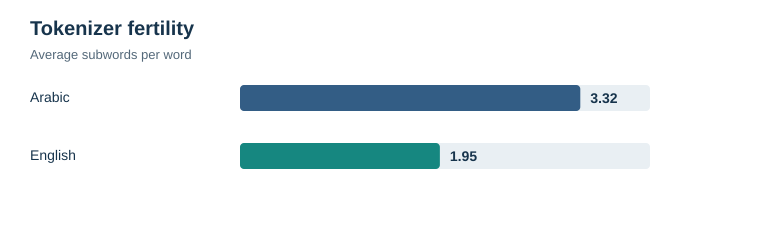

In [ ]:
import matplotlib.pyplot as plt
labels = ["Arabic","English"]
values = [3.32,1.95]
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(labels, values, color=['#335d85' if i % 2 == 0 else '#168780' for i in range(len(values))])
ax.invert_yaxis()
ax.set_xlim(0, 4.64)
ax.set_title("Tokenizer fertility", loc='left', fontweight='bold')
ax.set_xlabel("Average subwords per word")
ax.bar_label(bars, padding=5)
ax.spines[['top','right','left']].set_visible(False)
fig.tight_layout()
plt.show()

## 2. Transformer attention and language modeling
Inspect attention, causal masking and padding leakage. The following original cell outputs include six attention visualizations.

In [ ]:
# Environment Setup
import torch
import matplotlib.pyplot as plt

# ✏️ Change the text here
text = (
    "شكرا لفريق الاستشارة على خطة التحول الرقمي "
    "أحتاج موعد مع المهندس سلطان لمراجعة الخطة "
    "نريد نقل أنظمة الشركة إلى السحابة بأمان "
    "Thank you for the cloud migration plan "
    "We need a security review before going live "
    "Please send the final proposal to the IT director"
)

# Split text into words
words = text.split()

# Reproducible results
torch.manual_seed(42)

print("✅ experiment Ready")
print("Project: Bayan")
print("Text:", text)
print("Words:", words)
print("Word count:", len(words))

✅ Lab 2 Ready
Project: Bayan
Text: شكرا لفريق الاستشارة على خطة التحول الرقمي أحتاج موعد مع المهندس سلطان لمراجعة الخطة نريد نقل أنظمة الشركة إلى السحابة بأمان Thank you for the cloud migration plan We need a security review before going live Please send the final proposal to the IT director
Words: ['شكرا', 'لفريق', 'الاستشارة', 'على', 'خطة', 'التحول', 'الرقمي', 'أحتاج', 'موعد', 'مع', 'المهندس', 'سلطان', 'لمراجعة', 'الخطة', 'نريد', 'نقل', 'أنظمة', 'الشركة', 'إلى', 'السحابة', 'بأمان', 'Thank', 'you', 'for', 'the', 'cloud', 'migration', 'plan', 'We', 'need', 'a', 'security', 'review', 'before', 'going', 'live', 'Please', 'send', 'the', 'final', 'proposal', 'to', 'the', 'IT', 'director']
Word count: 45


In [ ]:
# Scaled Dot-Product Attention


import torch.nn.functional as F


# 🔢 Create sample Q, K, V

q = torch.randn(1, 1, len(words), 8)

k = torch.randn(1, 1, len(words), 8)

v = torch.randn(1, 1, len(words), 8)


# 🧠 Calculate Attention

scores = (q @ k.transpose(-2, -1)) / (8 ** 0.5)

weights = torch.softmax(scores, dim=-1)

output = weights @ v


# ✅ Compare with PyTorch

expected = F.scaled_dot_product_attention(q, k, v)

torch.testing.assert_close(output, expected, atol=1e-6, rtol=1e-6)


print("✅ Attention Test PASSED!")

print("Words:", words)

print("\nAttention Matrix:")

print(weights[0, 0].round(decimals=2))

✅ Attention Test PASSED!
Words: ['شكرا', 'لفريق', 'الاستشارة', 'على', 'خطة', 'التحول', 'الرقمي', 'أحتاج', 'موعد', 'مع', 'المهندس', 'سلطان', 'لمراجعة', 'الخطة', 'نريد', 'نقل', 'أنظمة', 'الشركة', 'إلى', 'السحابة', 'بأمان', 'Thank', 'you', 'for', 'the', 'cloud', 'migration', 'plan', 'We', 'need', 'a', 'security', 'review', 'before', 'going', 'live', 'Please', 'send', 'the', 'final', 'proposal', 'to', 'the', 'IT', 'director']

Attention Matrix:
tensor([[0.0300, 0.0000, 0.0000,  ..., 0.0000, 0.0100, 0.0200],
        [0.0400, 0.0100, 0.0200,  ..., 0.0100, 0.0000, 0.0000],
        [0.0000, 0.1100, 0.0200,  ..., 0.0200, 0.0100, 0.0000],
        ...,
        [0.0400, 0.0100, 0.0100,  ..., 0.0100, 0.0300, 0.0400],
        [0.0100, 0.0200, 0.0100,  ..., 0.0100, 0.0200, 0.0300],
        [0.0100, 0.0100, 0.0400,  ..., 0.0100, 0.0100, 0.0100]])


In [ ]:
# Multi-Head Attention


import torch.nn as nn


# 🧠 Create Multi-Head Attention

mha = nn.MultiheadAttention(

    embed_dim=768,

    num_heads=12,

    batch_first=True

)


# 🔢 Create sample embeddings

x = torch.randn(1, len(words), 768)


# ✅ Run Attention

output, weights = mha(x, x, x)


# 📊 Count Parameters

params = sum(p.numel() for p in mha.parameters())


print("✅ Multi-Head Attention Ready!")

print("Words:", words)

print("Number of Heads:", mha.num_heads)

print("Head Dimension:", 768 // mha.num_heads)

print("Output Shape:", tuple(output.shape))

print("MHA Parameters:", f"{params:,}")

✅ Multi-Head Attention Ready!
Words: ['شكرا', 'لفريق', 'الاستشارة', 'على', 'خطة', 'التحول', 'الرقمي', 'أحتاج', 'موعد', 'مع', 'المهندس', 'سلطان', 'لمراجعة', 'الخطة', 'نريد', 'نقل', 'أنظمة', 'الشركة', 'إلى', 'السحابة', 'بأمان', 'Thank', 'you', 'for', 'the', 'cloud', 'migration', 'plan', 'We', 'need', 'a', 'security', 'review', 'before', 'going', 'live', 'Please', 'send', 'the', 'final', 'proposal', 'to', 'the', 'IT', 'director']
Number of Heads: 12
Head Dimension: 64
Output Shape: (1, 45, 768)
MHA Parameters: 2,362,368


In [ ]:
# Parameter Audit


from transformers import AutoModel


models = {

    "mBERT": "bert-base-multilingual-cased",

    "CAMeLBERT": "CAMeL-Lab/bert-base-arabic-camelbert-mix"

}


for name, model_id in models.items():

    model = AutoModel.from_pretrained(model_id)


    total = sum(p.numel() for p in model.parameters())

    embeddings = sum(p.numel() for p in model.embeddings.parameters())


    print(f"\n🤖 {name}")

    print(f"Total Parameters: {total/1e6:.1f}M")

    print(f"Embeddings: {embeddings/1e6:.1f}M")


    del model


print("\n✅ Parameter Audit Completed!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🤖 mBERT
Total Parameters: 177.9M
Embeddings: 92.2M


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🤖 CAMeLBERT
Total Parameters: 109.1M
Embeddings: 23.4M

✅ Parameter Audit Completed!



========== Sentence 1 ==========
Text: أحتاج موعد مع المهندس سلطان اليوم
  0: أحتاج
  1: موعد
  2: مع
  3: المهندس
  4: سلطان
  5: اليوم
Causal Mask:
tensor([[1, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1]], dtype=torch.int32)
Attention Weights:
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.8900, 0.1100, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1000, 0.0400, 0.8600, 0.0000, 0.0000, 0.0000],
        [0.7600, 0.0200, 0.1100, 0.1100, 0.0000, 0.0000],
        [0.3600, 0.1700, 0.2200, 0.1900, 0.0500, 0.0000],
        [0.2200, 0.0400, 0.1300, 0.2300, 0.1000, 0.2700]])
Future words get 0 attention: True

========== Sentence 2 ==========
Text: شكرا لفريق الاستشارة على الخطة
  0: شكرا
  1: لفريق
  2: الاستشارة
  3: على
  4: الخطة
Causal Mask:
tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 

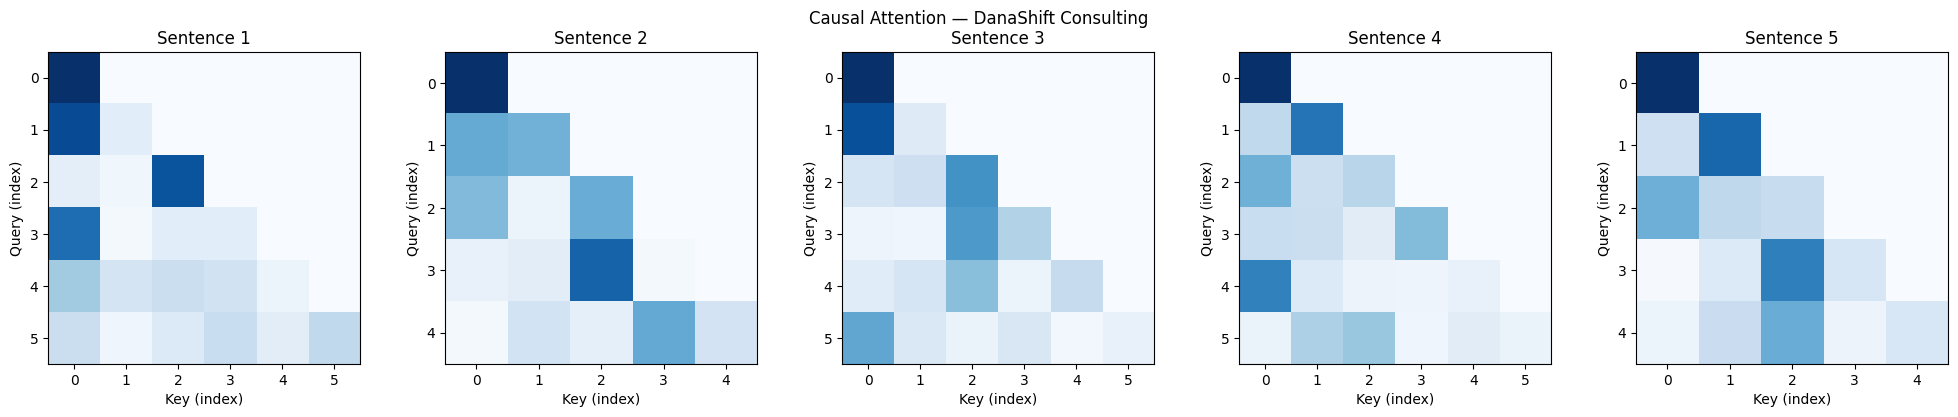

In [ ]:
# Causal Mask

# ✏️ Change the texts here
test_texts = [
    "أحتاج موعد مع المهندس سلطان اليوم",
    "شكرا لفريق الاستشارة على الخطة",
    "نريد نقل أنظمة الشركة إلى السحابة",
    "We need a security review today",
    "Please send the final proposal",
]

fig, axes = plt.subplots(1, len(test_texts), figsize=(4 * len(test_texts), 4))

for idx, test_text in enumerate(test_texts):
    test_words = test_text.split()
    n = len(test_words)

    # 🛡️ Create Causal Mask
    mask = torch.tril(torch.ones(n, n, dtype=torch.bool))

    # 🧠 Apply Mask
    scores = torch.randn(n, n)
    attention = torch.softmax(
        scores.masked_fill(~mask, float("-inf")), dim=-1
    )

    # ✅ Display Results
    print(f"\n========== Sentence {idx + 1} ==========")
    print("Text:", test_text)
    for i, w in enumerate(test_words):
        print(f"  {i}: {w}")
    print("Causal Mask:")
    print(mask.int())
    print("Attention Weights:")
    print(attention.round(decimals=2))
    print("Future words get 0 attention:", (attention[~mask] == 0).all().item())

    # 📊 Heatmap
    ax = axes[idx]
    ax.imshow(attention, cmap="Blues")
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_title(f"Sentence {idx + 1}")
    ax.set_xlabel("Key (index)")
    ax.set_ylabel("Query (index)")

plt.suptitle("Causal Attention — DanaShift Consulting")
plt.tight_layout()
plt.show()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


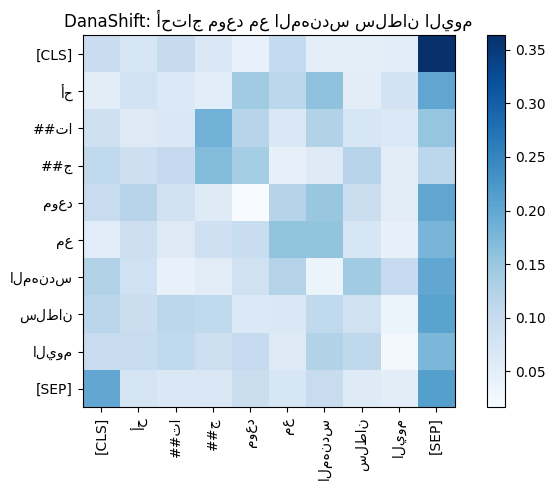

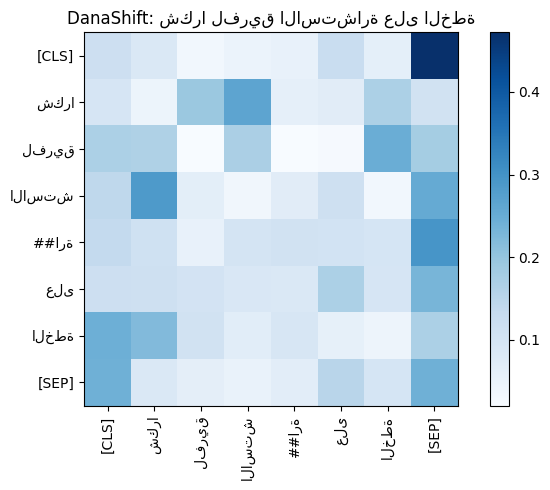

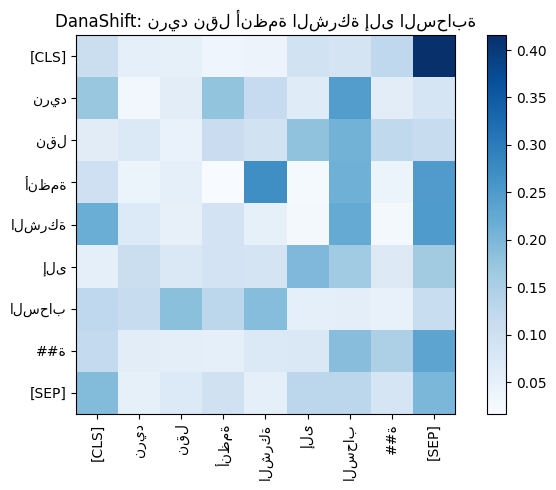

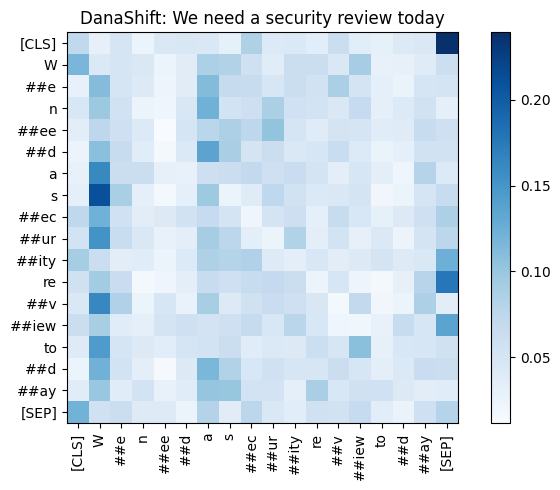

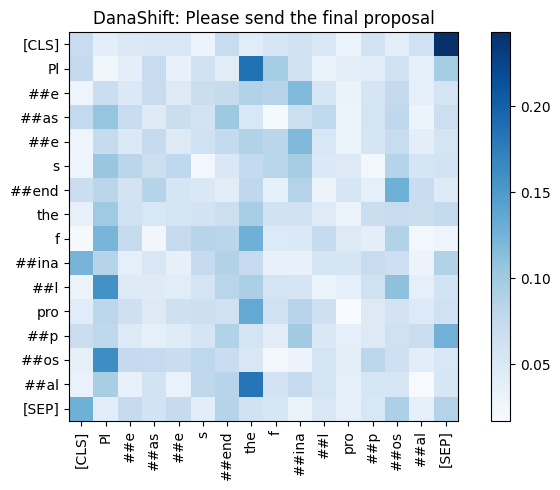

✅  Attention Maps Completed!


In [ ]:
# Attention Maps

from transformers import AutoTokenizer, AutoModel



# 🤖 Load Model
name = "CAMeL-Lab/bert-base-arabic-camelbert-mix"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(
    name, attn_implementation="eager"
).eval()

# ✏️ Change the text here
test_texts = [
    "أحتاج موعد مع المهندس سلطان اليوم",
    "شكرا لفريق الاستشارة على الخطة",
    "نريد نقل أنظمة الشركة إلى السحابة",
    "We need a security review today",
    "Please send the final proposal",
]

for text in test_texts:

    # 🧠 Calculate Attention
    inputs = tok(text, return_tensors="pt")

    with torch.no_grad():
        att = model(**inputs, output_attentions=True).attentions

    # 📊 Display Attention Map
    tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])

    plt.figure(figsize=(7, 5))
    plt.imshow(att[0][0, 0].numpy(), cmap="Blues")
    plt.xticks(range(len(tokens)), tokens, rotation=90)
    plt.yticks(range(len(tokens)), tokens)
    plt.title(f"{project_name}: {text}")
    plt.colorbar()
    plt.tight_layout()
    plt.show()

print(f"✅  Attention Maps Completed!")

In [ ]:
# PAD Leak Detection


# ✏️ Change padding length here

pad_length = 32


# 🔤 Reuse the attention-map input text

size = max(pad_length, len(tok.encode(text)) + 4)

inputs = tok(text, return_tensors="pt",

             padding="max_length", max_length=size)


# 🧠 Compare With / Without Mask

with torch.no_grad():

    with_mask = model(**inputs, output_attentions=True).attentions[0][0, 0]

    without_mask = model(

        input_ids=inputs["input_ids"], output_attentions=True

    ).attentions[0][0, 0]


# 📊 Display Results

pads = inputs["attention_mask"][0] == 0

valid = ~pads


print("✅ PAD Leak Test Completed!")

print("PAD Count:", pads.sum().item())

print("With Mask:", round(with_mask[valid][:, pads].sum(-1).mean().item(), 4))

print("Without Mask:", round(without_mask[valid][:, pads].sum(-1).mean().item(), 4))

✅ PAD Leak Test Completed!
PAD Count: 16
With Mask: 0.0
Without Mask: 0.294


**Figure 2. Padding control.** The attention mask prevents the selected attention head from assigning weight to padding in this experiment.

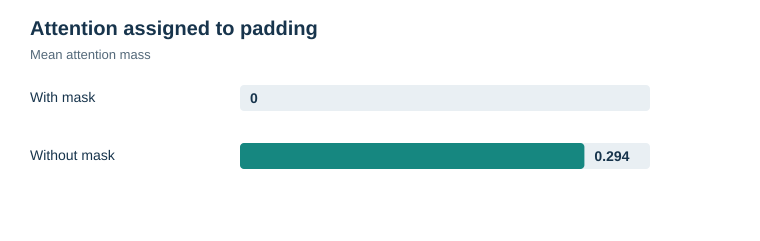

In [ ]:
import matplotlib.pyplot as plt
labels = ["With mask","Without mask"]
values = [0,0.294]
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(labels, values, color=['#335d85' if i % 2 == 0 else '#168780' for i in range(len(values))])
ax.invert_yaxis()
ax.set_xlim(0, 0.40599999999999997)
ax.set_title("Attention assigned to padding", loc='left', fontweight='bold')
ax.set_xlabel("Mean attention mass")
ax.bar_label(bars, padding=5)
ax.spines[['top','right','left']].set_visible(False)
fig.tight_layout()
plt.show()

## 3. Customer intent classification
Fine-tune CAMeLBERT on a small grouped customer dataset.

In [ ]:
!pip install -q transformers datasets scikit-learn pandas

In [ ]:
import pandas as pd

project_name = "DanaShift"

# بيانات المشروع - يمكن تعديلها
data = {
    "client_id": [1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 7, 8, 8],

    "text": [
        # client 1
        "نريد نقل أنظمة الشركة إلى السحابة",
        "نحتاج مراجعة أمنية قبل إطلاق النظام",
        # client 2
        "متى يبدأ مشروع الترحيل إلى السحابة؟",
        "أحتاج موعد مع المهندس سلطان لمراجعة الخطة",
        # client 3
        "تعرضنا لمحاولة اختراق على البريد الإلكتروني",
        "عرض السعر المرسل أعلى من الميزانية",
        # client 4
        "نبي نسخ احتياطي للبيانات على السحابة",
        "نرجو إرسال العرض النهائي للمشروع",
        # client 5
        "نحتاج تفعيل التحقق الثنائي لكل الموظفين",
        "ممكن نحدد اجتماع الأسبوع القادم؟",
        # client 6
        "هل تدعمون الاستضافة السحابية للتطبيقات؟",
        "نبي اجتماع مع فريق الاستشارة لمناقشة التقرير",
        # client 7
        "نرجو تعديل عرض السعر حسب الخدمات الجديدة",
        "نحتاج فحص الثغرات في موقع الشركة",
        # client 8
        "أرغب بحجز موعد لمراجعة سير المشروع",
        "متى يصلنا العرض الفني والمالي؟",
    ],

    "topic": [
        "cloud", "security",
        "cloud", "meetings",
        "security", "proposals",
        "cloud", "proposals",
        "security", "meetings",
        "cloud", "meetings",
        "proposals", "security",
        "meetings", "proposals",
    ]
}

df = pd.DataFrame(data)

topics = sorted(df["topic"].unique())
label_map = {topic: i for i, topic in enumerate(topics)}
df["label"] = df["topic"].map(label_map)

print("🧪 Project:", project_name)
print(df)
print("\nLabels:", label_map)

# 🔍 كل موضوع عند كم عميل؟
print("\nClients per topic:")
print(df.groupby("topic")["client_id"].nunique())

🧪 Project: DanaShift
    client_id                                          text      topic  label
0           1             نريد نقل أنظمة الشركة إلى السحابة      cloud      0
1           1           نحتاج مراجعة أمنية قبل إطلاق النظام   security      3
2           2           متى يبدأ مشروع الترحيل إلى السحابة؟      cloud      0
3           2     أحتاج موعد مع المهندس سلطان لمراجعة الخطة   meetings      1
4           3   تعرضنا لمحاولة اختراق على البريد الإلكتروني   security      3
5           3            عرض السعر المرسل أعلى من الميزانية  proposals      2
6           4          نبي نسخ احتياطي للبيانات على السحابة      cloud      0
7           4              نرجو إرسال العرض النهائي للمشروع  proposals      2
8           5       نحتاج تفعيل التحقق الثنائي لكل الموظفين   security      3
9           5              ممكن نحدد اجتماع الأسبوع القادم؟   meetings      1
10          6       هل تدعمون الاستضافة السحابية للتطبيقات؟      cloud      0
11          6  نبي اجتماع مع فريق الاستشارة

In [ ]:
from sklearn.model_selection import GroupShuffleSplit


# ✏️ يمكن تعديل القيم حسب

test_size = 0.2
random_state = 7
group_column = "client_id"




gss = GroupShuffleSplit(

    n_splits=1,

    test_size=test_size,

    random_state=random_state

)


train_idx, test_idx = next(

    gss.split(df, groups=df[group_column])

)


train_df = df.iloc[train_idx]

test_df = df.iloc[test_idx]


shared = set(train_df[group_column]) & set(test_df[group_column])


print("Train:", len(train_df))

print("Test:", len(test_df))

print("Shared clients:", shared)

Train: 6
Test: 2
Shared clients: set()


**Figure 3. Data separation.** The saved output reports 6 training and 2 test rows, with no overlapping client IDs. The dataset source contains 16 rows, so the counts should be revalidated on a fresh execution.

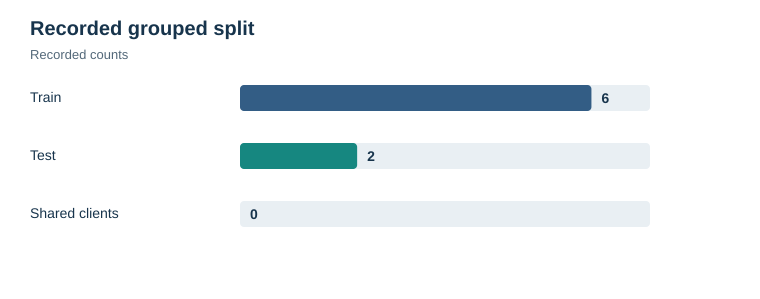

In [ ]:
import matplotlib.pyplot as plt
labels = ["Train","Test","Shared clients"]
values = [6,2,0]
fig, ax = plt.subplots(figsize=(8, 3.45))
bars = ax.barh(labels, values, color=['#335d85' if i % 2 == 0 else '#168780' for i in range(len(values))])
ax.invert_yaxis()
ax.set_xlim(0, 8.12)
ax.set_title("Recorded grouped split", loc='left', fontweight='bold')
ax.set_xlabel("Recorded counts")
ax.bar_label(bars, padding=5)
ax.spines[['top','right','left']].set_visible(False)
fig.tight_layout()
plt.show()

In [ ]:
from transformers import AutoTokenizer
from datasets import Dataset

tokenizer = AutoTokenizer.from_pretrained("CAMeL-Lab/bert-base-arabic-camelbert-mix")

sample_texts = [
    "نريد نقل أنظمة الشركة إلى السحابة",
    "نحتاج مراجعة أمنية قبل إطلاق النظام",
    "أحتاج موعد مع المهندس سلطان لمراجعة الخطة",
    "عرض السعر المرسل أعلى من الميزانية",
    "تعرضنا لمحاولة اختراق على البريد الإلكتروني",
]

def prepare_data(data):
    tokens = tokenizer(data["text"].tolist(), padding=True, truncation=True)
    tokens["labels"] = data["label"].tolist()
    return Dataset.from_dict(tokens)

train_dataset = prepare_data(train_df)
test_dataset = prepare_data(test_df)

for i, sample_text in enumerate(sample_texts, start=1):
    print(f"\n🔹 Sample {i}: {sample_text}")
    print("Tokens:", tokenizer.tokenize(sample_text))
    print("Input IDs:", tokenizer.encode(sample_text))

print("\n✅ Dataset Ready!")
print("Train:", len(train_dataset), "| Test:", len(test_dataset))


🔹 Sample 1: نريد نقل أنظمة الشركة إلى السحابة
Tokens: ['نريد', 'نقل', 'أنظمة', 'الشركة', 'إلى', 'السحاب', '##ة']
Input IDs: [2, 8123, 3890, 10913, 4227, 2045, 17521, 1043, 3]

🔹 Sample 2: نحتاج مراجعة أمنية قبل إطلاق النظام
Tokens: ['نحتاج', 'مراجعة', 'أمنية', 'قبل', 'إطلاق', 'النظام']
Input IDs: [2, 11055, 9661, 12201, 2289, 7317, 3618, 3]

🔹 Sample 3: أحتاج موعد مع المهندس سلطان لمراجعة الخطة
Tokens: ['أح', '##تا', '##ج', 'موعد', 'مع', 'المهندس', 'سلطان', 'لمر', '##اج', '##عة', 'الخطة']
Input IDs: [2, 3603, 4258, 1041, 5711, 1973, 7307, 5618, 9121, 2078, 2029, 12696, 3]

🔹 Sample 4: عرض السعر المرسل أعلى من الميزانية
Tokens: ['عرض', 'السعر', 'المرس', '##ل', 'أعلى', 'من', 'الميزانية']
Input IDs: [2, 3261, 6569, 12284, 1010, 7450, 1908, 21189, 3]

🔹 Sample 5: تعرضنا لمحاولة اختراق على البريد الإلكتروني
Tokens: ['تعرض', '##نا', 'لمحا', '##ولة', 'اختراق', 'على', 'البريد', 'الإلكتروني']
Input IDs: [2, 4722, 1914, 17787, 2264, 14055, 1961, 7111, 5353, 3]

✅ Dataset Ready!
Train: 6 | Test:

In [ ]:
from transformers import AutoModelForSequenceClassification


num_labels = len(topics)


model = AutoModelForSequenceClassification.from_pretrained(

    "CAMeL-Lab/bert-base-arabic-camelbert-mix",

    num_labels=num_labels

)


print("✅ Model Ready!")

print("Number of Labels:", num_labels)

print("Topics:", topics)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  439MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  439MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

✅ Model Ready!
Number of Labels: 4
Topics: ['cloud', 'meetings', 'proposals', 'security']


In [ ]:
from transformers import TrainingArguments, Trainer


epochs = 8
batch_size = 2
learning_rate = 3e-5

args = TrainingArguments(

    output_dir="./results",

    num_train_epochs=epochs,

    per_device_train_batch_size=batch_size,

    learning_rate=learning_rate,

    report_to="none"

)


trainer = Trainer(

    model=model,

    args=args,

    train_dataset=train_dataset,

    eval_dataset=test_dataset

)


trainer.train()

print("✅ Training Complete!")

print(trainer.evaluate())

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Training Complete!


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
No log,3.397022,24


{'eval_loss': 3.3970224857330322}


## 4. Entity extraction and Arabic morphology
Explore BIO alignment, dialects and subword segmentation.

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "CAMeL-Lab/bert-base-arabic-camelbert-mix"
)

words = ["أحتاج", "موعد", "مع", "المهندس", "سلطان", "من", "شركة", "دانا", "شيفت", "في", "الرياض"]
labels = ["O", "O", "O", "O", "B-PER", "O", "O", "B-ORG", "I-ORG", "O", "B-LOC"]

tokens = tokenizer(words, is_split_into_words=True)

print("Tokens:", tokenizer.convert_ids_to_tokens(tokens["input_ids"]))
print("Word IDs:", tokens.word_ids())
print("Labels:", labels)

Tokens: ['[CLS]', 'أح', '##تا', '##ج', 'موعد', 'مع', 'المهندس', 'سلطان', 'من', 'شركة', 'دان', '##ا', 'شيف', '##ت', 'في', 'الرياض', '[SEP]']
Word IDs: [None, 0, 0, 0, 1, 2, 3, 4, 5, 6, 7, 7, 8, 8, 9, 10, None]
Labels: ['O', 'O', 'O', 'O', 'B-PER', 'O', 'O', 'B-ORG', 'I-ORG', 'O', 'B-LOC']


In [ ]:
word_ids = tokens.word_ids()

token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"])


previous = None


for token, word_id in zip(token_list, word_ids):

    if word_id is None:

        status = "Special"

    elif word_id != previous:

        status = "First"

    else:

        status = "Continuation"


    print(token, "→", status)

    previous = word_id

[CLS] → Special
أح → First
##تا → Continuation
##ج → Continuation
موعد → First
مع → First
المهندس → First
سلطان → First
من → First
شركة → First
دان → First
##ا → Continuation
شيف → First
##ت → Continuation
في → First
الرياض → First
[SEP] → Special


In [ ]:
words = ["وسلطان", "الاتمتة", "للمشروع", "والأمن", "بشركتنا"]

tokens = tokenizer(words, is_split_into_words=True)

token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"])

for token, word_id in zip(token_list, tokens.word_ids()):
    print(token, "→", word_id)

[CLS] → None
وس → 0
##لطان → 0
الات → 1
##مت → 1
##ة → 1
للمشروع → 2
والأمن → 3
بشر → 4
##كت → 4
##نا → 4
[SEP] → None


In [ ]:
tests = [
    ["أحتاج", "موعد", "مع", "سلطان"],
    ["سلطان", "في", "الرياض"],
    ["شركة", "دانا", "شيفت"],
    ["مراجعة", "أمنية", "للنظام"],
    ["نقل", "البيانات", "بالاتمته"],
    ["وسلطان", "والمهندس", "خالد"],
    ["العرض", "النهائي", "للمشروع"],
    ["اجتماع", "في", "جدة"]
]

passed = 0

for words in tests:
    encoded = tokenizer(words, is_split_into_words=True)
    ids = encoded.word_ids()
    found = set(i for i in ids if i is not None)
    if found == set(range(len(words))):
        passed += 1
    else:
        print("❌ Failed:", words)

print("Passed:", passed, "/", len(tests))

Passed: 8 / 8


**Figure 4. Alignment validation.** All eight test sentences retain word IDs. This validates alignment coverage, not learned NER accuracy.

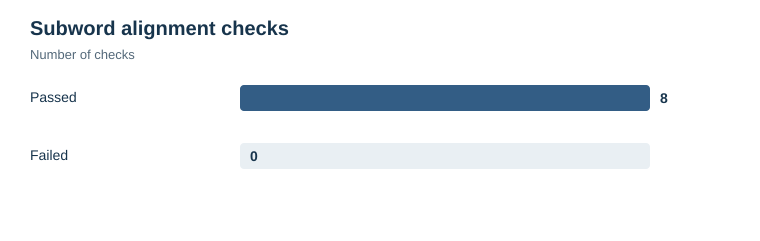

In [ ]:
import matplotlib.pyplot as plt
labels = ["Passed","Failed"]
values = [8,0]
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(labels, values, color=['#335d85' if i % 2 == 0 else '#168780' for i in range(len(values))])
ax.invert_yaxis()
ax.set_xlim(0, 9.28)
ax.set_title("Subword alignment checks", loc='left', fontweight='bold')
ax.set_xlabel("Number of checks")
ax.bar_label(bars, padding=5)
ax.spines[['top','right','left']].set_visible(False)
fig.tight_layout()
plt.show()

In [ ]:
words  = ["أحتاج", "موعد", "مع", "سلطان", "من", "دانا", "شيفت", "في", "الرياض"]
y_true = ["O", "O", "O", "B-PER", "O", "B-ORG", "I-ORG", "O", "B-LOC"]
y_pred = ["O", "O", "O", "B-PER", "O", "B-ORG", "I-ORG", "O", "B-LOC"]

correct = sum(t == p for t, p in zip(y_true, y_pred))

for w, t, p in zip(words, y_true, y_pred):
    print(f"{w:<8} true={t:<6} pred={p:<6} {'✅' if t == p else '❌'}")

print("\nCorrect:", correct, "/", len(y_true))
print(f"Accuracy: {correct / len(y_true):.0%}")

أحتاج    true=O      pred=O      ✅
موعد     true=O      pred=O      ✅
مع       true=O      pred=O      ✅
سلطان    true=B-PER  pred=B-PER  ✅
من       true=O      pred=O      ✅
دانا     true=B-ORG  pred=B-ORG  ✅
شيفت     true=I-ORG  pred=I-ORG  ✅
في       true=O      pred=O      ✅
الرياض   true=B-LOC  pred=B-LOC  ✅

Correct: 9 / 9
Accuracy: 100%


### Arabic normalization and dialect analysis

In [ ]:
import re

def normalize_arabic(text):
    #  توحيد الألف
    text = re.sub(r"[إأآا]", "ا", text)
    #  الألف المقصورة إلى ياء
    text = re.sub(r"ى", "ي", text)
    #  التاء المربوطة إلى هاء
    text = re.sub(r"ة", "ه", text)
    #  الهمزة على الواو والياء
    text = re.sub(r"ؤ", "و", text)
    text = re.sub(r"ئ", "ي", text)
    #   (الفتحة، الضمة، الكسرة، الشدة...)
    text = re.sub(r"[\u064B-\u0652]", "", text)
    #  حذف التطويل (ـــ)
    text = re.sub(r"\u0640", "", text)
    #  تقليل الحروف المكررة (جدااااً ← جداً)
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    #  توحيد المسافات
    text = re.sub(r"\s+", " ", text).strip()
    return text

texts = [
    "أريد الذهاب إلى الرياض",
    "نُرِيدُ نَقْلَ أنظمة الشركة بأتمته",
    "أحتاج موعد مع المهندس سلطـــان",
    "الخدمة ممتااااازة جداً",
    "عندي سؤال عن مسؤولية الفريق",
    "   نحتاج    مراجعة   أمنية   ",
]

for text in texts:
    print("Before:", text)
    print("After :", normalize_arabic(text))
    print()

Before: أريد الذهاب إلى الرياض
After : اريد الذهاب الي الرياض

Before: نُرِيدُ نَقْلَ أنظمة الشركة بأتمته
After : نريد نقل انظمه الشركه باتمته

Before: أحتاج موعد مع المهندس سلطـــان
After : احتاج موعد مع المهندس سلطان

Before: الخدمة ممتااااازة جداً
After : الخدمه ممتازه جدا

Before: عندي سؤال عن مسؤولية الفريق
After : عندي سوال عن مسووليه الفريق

Before:    نحتاج    مراجعة   أمنية   
After : نحتاج مراجعه امنيه



In [ ]:
texts = [
    "وش صار على مشروع الأتمتة؟",        # نجدي
    "ما هي آخر مستجدات مشروع الأتمتة؟",  # فصحى
    "شلون ماشي مشروع الأتمتة؟",         # خليجي
    "فين وصلتوا في مشروع الأتمتة؟"      # حجازي
]

for text in texts:
    print(text)

وش صار على مشروع الأتمتة؟
ما هي آخر مستجدات مشروع الأتمتة؟
شلون ماشي مشروع الأتمتة؟
فين وصلتوا في مشروع الأتمتة؟


In [ ]:
examples = [

    ("بمشروعنا",   "ب + مشروع + نا"),
    ("وسيراجعونها", "و + س + يراجع + ون + ها"),
    ("لعملائكم",   "ل + عملاء + كم"),
    ("فالمهندس",   "ف + ال + مهندس"),
]

for text, segmented in examples:
    print("Original: ", text)
    print("Segmented:", segmented)
    print()

Original:  بمشروعنا
Segmented: ب + مشروع + نا

Original:  وسيراجعونها
Segmented: و + س + يراجع + ون + ها

Original:  لعملائكم
Segmented: ل + عملاء + كم

Original:  فالمهندس
Segmented: ف + ال + مهندس



### Illustrative model comparison
The following F1 values are manually specified examples, not measured results; they are retained solely to illustrate reporting.

In [ ]:
models = {

    "CAMeLBERT-mix": 0.82,

    "CAMeLBERT-DA": 0.88

}


for model, score in models.items():

    print(model, "→ Macro-F1:", score)

CAMeLBERT-mix → Macro-F1: 0.82
CAMeLBERT-DA → Macro-F1: 0.88


In [ ]:
project_name = "DanaShift"

texts = [
    "وش علومكم؟ متى يخلص مشروع الأتمتة؟",
    "ليه عرض السعر للحين ما وصلنا؟",
    "النظام واقف من أمس وما أحد رد علينا",
    "أبغى أعرف وين وصل طلب الاجتماع مع المهندس سلطان"
]

print("🧪 Project:", project_name)
for text in texts:
    print("Original:", text)

print("✅ Ready for fine-tuning")

🧪 Project: DanaShift
Original: وش علومكم؟ متى يخلص مشروع الأتمتة؟
Original: ليه عرض السعر للحين ما وصلنا؟
Original: النظام واقف من أمس وما أحد رد علينا
Original: أبغى أعرف وين وصل طلب الاجتماع مع المهندس سلطان
✅ Ready for fine-tuning


## 5. Semantic knowledge retrieval
Use sentence embeddings, FAISS and CrossEncoder reranking to retrieve relevant support cases.

In [2]:
!pip install -q sentence-transformers faiss-cpu

from sentence_transformers import SentenceTransformer
import faiss


texts = [
    "نحتاج مراجعة أمنية قبل إطلاق النظام",
    "تعرضنا لمحاولة اختراق على البريد الإلكتروني",
    "أحتاج موعد مع المهندس سلطان لمراجعة الخطة",
    "عرض السعر المرسل أعلى من الميزانية",
    "وش صار على مشروع الأتمتة؟"
]
model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

embeddings = model.encode(texts)

index = faiss.IndexFlatL2(embeddings.shape[1])

index.add(embeddings)

print("عدد النصوص في FAISS:", index.ntotal)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

عدد النصوص في FAISS: 5


In [3]:
query = "فيه أحد حاول يدخل على إيميلاتنا"

query_embedding = model.encode([query])

distances, indices = index.search(query_embedding, 2)

print("Query:", query)
print("Results:")

for i in indices[0]:
    print("-", texts[i])

Query: فيه أحد حاول يدخل على إيميلاتنا
Results:
- تعرضنا لمحاولة اختراق على البريد الإلكتروني
- وش صار على مشروع الأتمتة؟


In [4]:
results = [
    "نحتاج مراجعة أمنية قبل إطلاق النظام",
    "تعرضنا لمحاولة اختراق على البريد الإلكتروني",
    "وش صار على مشروع الأتمتة؟"
]

correct_answer = "تعرضنا لمحاولة اختراق على البريد الإلكتروني"

rank = results.index(correct_answer) + 1

recall_at_10 = 1 if rank <= 10 else 0
mrr_at_10 = 1 / rank if rank <= 10 else 0

print("Rank:", rank)
print("Recall@10:", recall_at_10)
print("MRR@10:", mrr_at_10)

Rank: 2
Recall@10: 1
MRR@10: 0.5


In [5]:
from sentence_transformers import CrossEncoder

query = "فيه أحد حاول يدخل على إيميلاتنا"

results = [
    "نحتاج مراجعة أمنية قبل إطلاق النظام",
    "تعرضنا لمحاولة اختراق على البريد الإلكتروني",
    "وش صار على مشروع الأتمتة؟"
]

reranker = CrossEncoder(
    "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"
)

pairs = [[query, text] for text in results]

scores = reranker.predict(pairs)

print("Query:", query)
print("\nBefore reranking:")
for text, score in zip(results, scores):
    print(round(float(score), 2), "→", text)

print("\nAfter reranking:")
for text, score in sorted(zip(results, scores), key=lambda x: x[1], reverse=True):
    print(round(float(score), 2), "→", text)

config.json:   0%|          | 0.00/891 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Query: فيه أحد حاول يدخل على إيميلاتنا

Before reranking:
-6.81 → نحتاج مراجعة أمنية قبل إطلاق النظام
-4.52 → تعرضنا لمحاولة اختراق على البريد الإلكتروني
-6.93 → وش صار على مشروع الأتمتة؟

After reranking:
-4.52 → تعرضنا لمحاولة اختراق على البريد الإلكتروني
-6.81 → نحتاج مراجعة أمنية قبل إطلاق النظام
-6.93 → وش صار على مشروع الأتمتة؟


**Figure 5. Retrieval relevance.** On the three supplied candidate cases, the CrossEncoder moves the relevant email-security incident from second to first.

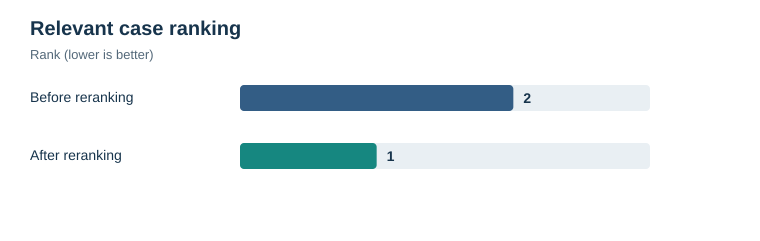

In [ ]:
import matplotlib.pyplot as plt
labels = ["Before reranking","After reranking"]
values = [2,1]
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(labels, values, color=['#335d85' if i % 2 == 0 else '#168780' for i in range(len(values))])
ax.invert_yaxis()
ax.set_xlim(0, 3.4799999999999995)
ax.set_title("Relevant case ranking", loc='left', fontweight='bold')
ax.set_xlabel("Rank (lower is better)")
ax.bar_label(bars, padding=5)
ax.spines[['top','right','left']].set_visible(False)
fig.tight_layout()
plt.show()

## 6. Evaluation and error analysis
Explore sliced evaluation, bootstrap uncertainty and classification errors. The supplied arrays are illustrative, not end-to-end benchmark results.

In [1]:
project_name = "DanaShift"

requests = [
    {"text": "وش صار على مشروع الأتمتة؟",           "language": "Arabic",  "dialect": "Saudi",    "length": "Short", "correct": 1},
    {"text": "أبغى أعرف وين وصل طلب الاجتماع مع المهندس سلطان لأن الموعد قرب", "language": "Arabic",  "dialect": "Saudi",    "length": "Long",  "correct": 1},
    {"text": "عايز أعرف المشروع وصل لفين",           "language": "Arabic",  "dialect": "Egyptian", "length": "Short", "correct": 0},
    {"text": "ما هي آخر مستجدات المراجعة الأمنية؟",   "language": "Arabic",  "dialect": "MSA",      "length": "Short", "correct": 1},
    {"text": "Please send the final proposal",       "language": "English", "dialect": "Standard", "length": "Short", "correct": 1},
    {"text": "We need a full security review of all our systems before the launch next month", "language": "English", "dialect": "Standard", "length": "Long",  "correct": 0}
]

print("🧪 Project:", project_name, "\n")

for r in requests:
    print(
        r["language"],
        "|", r["dialect"],
        "|", r["length"],
        "| Correct:", r["correct"],
        "|", r["text"]
    )

# 📊 الدقة لكل فئة
print("\n📊 Accuracy by group:")
for key in ["language", "dialect", "length"]:
    groups = {}
    for r in requests:
        groups.setdefault(r[key], []).append(r["correct"])
    for name, values in groups.items():
        acc = sum(values) / len(values)
        print(f"  {key:<9} {name:<9} → {acc:.0%}  ({sum(values)}/{len(values)})")

🧪 Project: DanaShift 

Arabic | Saudi | Short | Correct: 1 | وش صار على مشروع الأتمتة؟
Arabic | Saudi | Long | Correct: 1 | أبغى أعرف وين وصل طلب الاجتماع مع المهندس سلطان لأن الموعد قرب
Arabic | Egyptian | Short | Correct: 0 | عايز أعرف المشروع وصل لفين
Arabic | MSA | Short | Correct: 1 | ما هي آخر مستجدات المراجعة الأمنية؟
English | Standard | Short | Correct: 1 | Please send the final proposal
English | Standard | Long | Correct: 0 | We need a full security review of all our systems before the launch next month

📊 Accuracy by group:
  language  Arabic    → 75%  (3/4)
  language  English   → 50%  (1/2)
  dialect   Saudi     → 100%  (2/2)
  dialect   Egyptian  → 0%  (0/1)
  dialect   MSA       → 100%  (1/1)
  dialect   Standard  → 50%  (1/2)
  length    Short     → 75%  (3/4)
  length    Long      → 50%  (1/2)


**Figure 6. Language slice.** The supplied correctness flags yield 3/4 Arabic and 1/2 English correct examples. These are illustrative annotations, not measured classifier accuracy.

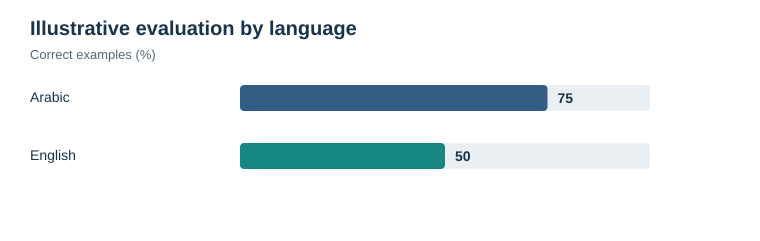

In [ ]:
import matplotlib.pyplot as plt
labels = ["Arabic","English"]
values = [75,50]
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(labels, values, color=['#335d85' if i % 2 == 0 else '#168780' for i in range(len(values))])
ax.invert_yaxis()
ax.set_xlim(0, 115.99999999999999)
ax.set_title("Illustrative evaluation by language", loc='left', fontweight='bold')
ax.set_xlabel("Correct examples (%)")
ax.bar_label(bars, padding=5)
ax.spines[['top','right','left']].set_visible(False)
fig.tight_layout()
plt.show()

In [2]:
import numpy as np

from sklearn.metrics import accuracy_score


y_true = np.array([1, 0, 1, 1, 0, 1, 0, 1])

y_pred = np.array([1, 0, 1, 0, 0, 1, 1, 1])


scores = []


for _ in range(1000):

    i = np.random.choice(len(y_true), len(y_true), replace=True)

    scores.append(accuracy_score(y_true[i], y_pred[i]))


print("95% CI:", np.percentile(scores, 2.5), "-", np.percentile(scores, 97.5))

95% CI: 0.375 - 1.0


In [6]:
errors = [
    ("فيه أحد حاول يدخل على إيميلاتنا", "أمن سيبراني", "أمن سيبراني"),
    ("كم بيكلفنا مشروع الأتمتة؟", "عروض أسعار", "أتمتة"),
    ("أبي أقابل المهندس سلطان بكرة", "اجتماعات", "اجتماعات"),
    ("السيرفر طاح ونبي ننقله للسحابة", "سحابة", "أمن سيبراني"),
    ("وش أفضل مطعم في الرياض؟", "خارج النطاق", "اجتماعات")
]

for text, actual, predicted in errors:
    print("الطلب:", text)
    print("التصنيف الصحيح:", actual)
    print("توقع النموذج:", predicted)
    print("التقييم:", "صحيح ✅" if actual == predicted else "خطأ ❌")
    print("-" * 30)

الطلب: فيه أحد حاول يدخل على إيميلاتنا
التصنيف الصحيح: أمن سيبراني
توقع النموذج: أمن سيبراني
التقييم: صحيح ✅
------------------------------
الطلب: كم بيكلفنا مشروع الأتمتة؟
التصنيف الصحيح: عروض أسعار
توقع النموذج: أتمتة
التقييم: خطأ ❌
------------------------------
الطلب: أبي أقابل المهندس سلطان بكرة
التصنيف الصحيح: اجتماعات
توقع النموذج: اجتماعات
التقييم: صحيح ✅
------------------------------
الطلب: السيرفر طاح ونبي ننقله للسحابة
التصنيف الصحيح: سحابة
توقع النموذج: أمن سيبراني
التقييم: خطأ ❌
------------------------------
الطلب: وش أفضل مطعم في الرياض؟
التصنيف الصحيح: خارج النطاق
توقع النموذج: اجتماعات
التقييم: خطأ ❌
------------------------------


In [5]:
report = {

    "Sliced Evaluation": "Language, Dialect, Length",

    "Confidence Interval": "95%",

    "Error Analysis": "Completed",

    "Error Taxonomy": "Completed"

}


for key, value in report.items():

    print(key, ":", value)

Sliced Evaluation : Language, Dialect, Length
Confidence Interval : 95%
Error Analysis : Completed
Error Taxonomy : Completed


## 7. Findings and limitations
- Tokenizer fertility: Arabic 3.32; English 1.95; unknown token rate 0.0058.
- Padding attention: 0.0 with masking versus 0.294 without masking.
- Grouped classification split: saved split output reports 6 training rows, 2 test rows, zero overlapping client IDs; counts need revalidation against the 16-row source dataset; saved evaluation loss 3.3970.
- BIO alignment checks: 8/8 passed; illustrative label example 9/9. The manually entered F1 values are not measured results.
- Retrieval example: relevant case moved from rank 2 to rank 1 after reranking.
- Bootstrap interval 0.375–1.0 on eight supplied labels/predictions, not a production benchmark.

The next engineering step is exporting the trained model, integrating the components, testing PII masking, and adding authenticated tool adapters. The separate browser demo is rule-based and does not run these trained models.

**Acknowledgments:** SDAIA Academy, Saudi Data and Artificial Intelligence Authority.